Setting Path to the dataset.

In [ ]:
import pandas as pd
path = '/content/sample_data/Student Depression Dataset.csv'

Importing libraries for ANN

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LeakyReLU
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

Loading dataset and Preprocessing.

In [ ]:
df = pd.read_csv(path)

df.drop(columns=['id', 'Work Pressure', 'Job Satisfaction'], inplace=True)

df = df.dropna()

binary_cols = ['Gender', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']
for col in binary_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

df = pd.get_dummies(df, columns=['City', 'Profession', 'Sleep Duration', 'Dietary Habits', 'Degree'], drop_first=True)

Feature Selection and Train Test split.

In [ ]:
X = df.drop('Depression', axis=1)
y = df['Depression']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

ANN Model

In [ ]:
model = Sequential()
model.add(Dense(128, input_shape=(X_train.shape[1],)))
model.add(LeakyReLU(alpha=0.1))
model.add(Dropout(0.3))

model.add(Dense(64))
model.add(tf.keras.layers.Activation('tanh'))
model.add(Dropout(0.2))

model.add(Dense(32))
model.add(LeakyReLU(alpha=0.1))

model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Training and Evaluation

Epoch 1/7
628/628 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7822 - loss: 0.4615 - val_accuracy: 0.8508 - val_loss: 0.3567
Epoch 2/7
628/628 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8371 - loss: 0.3654 - val_accuracy: 0.8571 - val_loss: 0.3518
Epoch 3/7
628/628 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8462 - loss: 0.3527 - val_accuracy: 0.8504 - val_loss: 0.3511
Epoch 4/7
628/628 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8501 - loss: 0.3490 - val_accuracy: 0.8553 - val_loss: 0.3515
Epoch 5/7
628/628 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8513 - loss: 0.3425 - val_accuracy: 0.8481 - val_loss: 0.3559
Epoch 6/7
628/628 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8509 - loss: 0.3381 - val_accuracy: 0.8526 - val_loss: 0.3579
Epoch 7/7
628/628 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8534 - loss: 0.3402 - val_accuracy: 0.8535 - val_loss: 0.3527
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Accuracy: 0.8473118279569892
              precision    recall  f1-sc

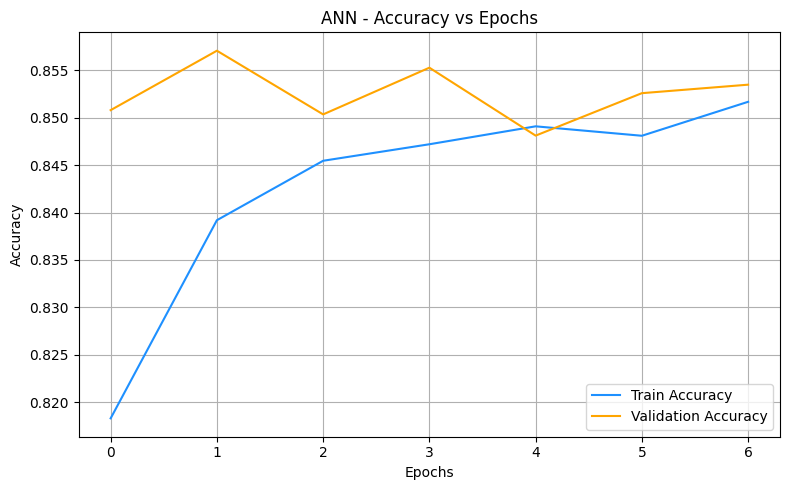

175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


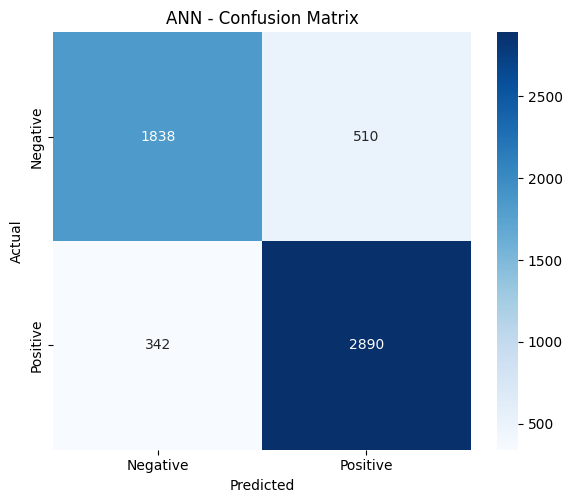

In [ ]:
ann_model = model.fit(X_train, y_train, epochs=7, batch_size=32, validation_split=0.1, verbose=1)

y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype("int32")

print("\nAccuracy:", accuracy_score(y_test, y_pred_classes))
print(classification_report(y_test, y_pred_classes))
train_acc = ann_model.history['accuracy']
val_acc = ann_model.history['val_accuracy']
epochs = range(len(train_acc))

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, label='Train Accuracy', color='dodgerblue')
plt.plot(epochs, val_acc, label='Validation Accuracy', color='orange')
plt.title('ANN - Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

y_pred = (model.predict(X_test) > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', square=True,
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])

plt.title('ANN - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

Importing libraries for CNN

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim

Loading dataset and Preprocessing.

In [ ]:
data = pd.read_csv(path)

data.drop(columns=['id', 'Work Pressure', 'Job Satisfaction'], inplace=True)
y = data['Depression']
X = data.drop(columns=['Depression'])

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns

num_imputer = SimpleImputer(strategy='mean')
X_numeric = pd.DataFrame(num_imputer.fit_transform(X[numeric_cols]), columns=numeric_cols)

X_categorical = pd.get_dummies(X[categorical_cols], drop_first=True)

X_processed = pd.concat([X_numeric, X_categorical], axis=1)

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_processed, y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_resampled)

# Reshaping into 2D grid
import math
num_features = X_scaled.shape[1]
target_size = math.ceil(np.sqrt(num_features)) ** 2
padding_size = target_size - num_features
X_padded = np.pad(X_scaled, ((0, 0), (0, padding_size)), mode='constant')
side = int(math.sqrt(target_size))
X_2d = X_padded.reshape(-1, 1, side, side)

# Converting to PyTorch tensors
X_tensor = torch.tensor(X_2d, dtype=torch.float32)
y_tensor = torch.tensor(y_resampled.values, dtype=torch.float32).unsqueeze(1)

Train Test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

CNN Model

In [ ]:
class CNNClassifier(nn.Module):
    def __init__(self):
        super(CNNClassifier, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        flattened_size = 32 * (side // 4) * (side // 4)
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flattened_size, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.fc(self.cnn(x))

model = CNNClassifier()
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

Training and Evaluation

Epoch 5, Loss: 0.6895, Train Acc: 0.5045, Val Acc: 0.5295
Epoch 10, Loss: 0.6723, Train Acc: 0.5948, Val Acc: 0.6197
Epoch 15, Loss: 0.6103, Train Acc: 0.7075, Val Acc: 0.7376
Epoch 20, Loss: 0.5259, Train Acc: 0.7443, Val Acc: 0.7807
Epoch 25, Loss: 0.4574, Train Acc: 0.7970, Val Acc: 0.7917
Epoch 30, Loss: 0.4217, Train Acc: 0.8160, Val Acc: 0.8127
Epoch 35, Loss: 0.3978, Train Acc: 0.8245, Val Acc: 0.8318
Epoch 40, Loss: 0.3778, Train Acc: 0.8364, Val Acc: 0.8401
Epoch 45, Loss: 0.3588, Train Acc: 0.8433, Val Acc: 0.8450
Epoch 50, Loss: 0.3524, Train Acc: 0.8463, Val Acc: 0.8494
Epoch 55, Loss: 0.3420, Train Acc: 0.8507, Val Acc: 0.8529
Epoch 60, Loss: 0.3360, Train Acc: 0.8533, Val Acc: 0.8477
Epoch 65, Loss: 0.3274, Train Acc: 0.8585, Val Acc: 0.8549
Epoch 70, Loss: 0.3223, Train Acc: 0.8603, Val Acc: 0.8577
Epoch 75, Loss: 0.4402, Train Acc: 0.8111, Val Acc: 0.8178
Epoch 80, Loss: 0.3743, Train Acc: 0.8304, Val Acc: 0.8563
Epoch 85, Loss: 0.3343, Train Acc: 0.8541, Val Acc: 0.856

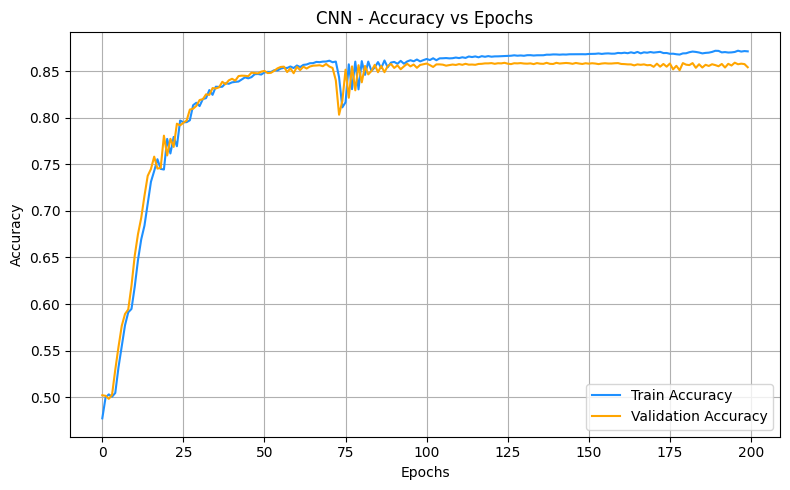


Confusion Matrix:
 [[2790  491]
 [ 462 2792]]

Classification Report:
               precision    recall  f1-score   support

         0.0     0.8579    0.8504    0.8541      3281
         1.0     0.8504    0.8580    0.8542      3254

    accuracy                         0.8542      6535
   macro avg     0.8542    0.8542    0.8542      6535
weighted avg     0.8542    0.8542    0.8542      6535



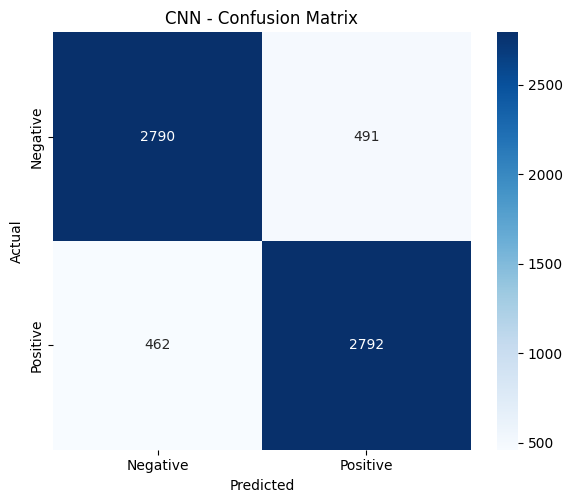

In [ ]:
train_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(1, 201):
    model.train()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        train_preds = (torch.sigmoid(outputs) >= 0.5).float()
        train_acc = (train_preds == y_train).float().mean().item()
        train_accuracies.append(train_acc)
        train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_test)
        val_preds = (torch.sigmoid(val_outputs) >= 0.5).float()
        val_acc = (val_preds == y_test).float().mean().item()
        val_accuracies.append(val_acc)

    if epoch % 5 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

model.eval()
with torch.no_grad():
    y_pred_logits = model(X_test)
    y_pred_probs = torch.sigmoid(y_pred_logits)
    y_pred = (y_pred_probs >= 0.5).float()

cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, digits=4)

epochs = range(len(train_accuracies))
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label='Train Accuracy', color='dodgerblue')
plt.plot(epochs, val_accuracies, label='Validation Accuracy', color='orange')
plt.title('CNN - Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", report)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', square=True,
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('CNN - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()
